# Segmentasi Morfologi Penguin Antarktika Berdasarkan Ukuran Tubuh Menggunakan Algoritma K-Means Clustering

**Ujian Akhir Semester — Data Mining (Soal No. 13, Kelompok B: Clustering)**

| | |
|---|---|
| **Nama** | Dicky Irawan |
| **NIM** | 2023.57201.054 |
| **Program Studi** | Sistem Informasi — Institut Teknologi Mojosari |
| **Dataset** | Palmer Penguins (Horst, Hill, & Gorman, 2020) |
| **Metode** | K-Means Clustering |
| **Metrik evaluasi** | Silhouette Score |
| **Tools** | Python 3 di Google Colab: pandas, NumPy, scikit-learn, matplotlib |

---

### Latar belakang singkat

Ukuran tubuh hewan, seperti panjang paruh, panjang sirip, dan massa tubuh, mencerminkan cara hidup dan sumber makanannya. Pada penguin di Kepulauan Palmer, Antarktika, ketiga spesies *Pygoscelis* (Adelie, Chinstrap, dan Gentoo) hidup berdampingan tetapi memiliki bentuk tubuh yang berbeda (Gorman et al., 2014). Pertanyaannya: **jika label spesies disembunyikan, apakah pengelompokan otomatis berdasarkan ukuran tubuh saja mampu menemukan kelompok yang bermakna?** Pertanyaan ini dijawab dengan *clustering*, yaitu teknik *unsupervised learning* yang mengelompokkan data tanpa label.

### Tujuan analisis

1. Mengidentifikasi karakteristik dan kualitas dataset Palmer Penguins serta menyiapkannya untuk clustering (penanganan data kosong, pemeriksaan duplikat dan outlier, standardisasi).
2. Menentukan jumlah cluster (*k*) yang optimal menggunakan Elbow Method dan Silhouette Score.
3. Mengelompokkan penguin berdasarkan panjang paruh, kedalaman paruh, panjang sirip, dan massa tubuh menggunakan algoritma K-Means.
4. Mengevaluasi kualitas cluster menggunakan Silhouette Score dan menginterpretasikan profil karakteristik fisik setiap cluster.
5. Membandingkan hasil cluster dengan spesies asli untuk menilai sejauh mana K-Means mampu mengenali kelompok alami tanpa label.

### Alur analisis

`Pengumpulan data → Pemahaman data & EDA → Preprocessing → Penentuan k → Pemodelan K-Means → Evaluasi (Silhouette) → Interpretasi & validasi → Kesimpulan`

---
## 1. Persiapan dan Memuat Data

Dataset dimuat langsung dari repositori GitHub resmi paket **palmerpenguins** (https://allisonhorst.github.io/palmerpenguins/). Versi yang digunakan adalah tabel `penguins` (8 kolom), yaitu versi yang sudah dirapikan oleh penyusun paket.

Semua grafik juga disimpan ke folder `gambar_jurnal/` (resolusi 300 dpi) agar dapat langsung dipakai dalam artikel jurnal.

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score,
                             normalized_mutual_info_score)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# Gaya grafik: sederhana, latar putih, grid tipis — cocok untuk cetak jurnal
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.family": "serif", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#898781", "axes.labelcolor": "#0b0b0b",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "legend.frameon": False,
})

# Warna tetap per spesies/cluster (palet aman buta warna) + bentuk penanda sebagai penguat
SPECIES = ["Adelie", "Chinstrap", "Gentoo"]
COLORS = {"Adelie": "#2a78d6", "Chinstrap": "#eb6834", "Gentoo": "#1baf7a"}
MARKERS = {"Adelie": "o", "Chinstrap": "s", "Gentoo": "^"}
INK, MUTED = "#0b0b0b", "#898781"

OUT_DIR = "gambar_jurnal"
os.makedirs(OUT_DIR, exist_ok=True)

def simpan(fig, nama):
    fig.savefig(os.path.join(OUT_DIR, nama))

import sys, sklearn, matplotlib
print("Versi perangkat lunak (dicantumkan di artikel jurnal, subbab 2.3):")
print(f"  Python       : {sys.version.split()[0]}")
print(f"  pandas       : {pd.__version__}")
print(f"  NumPy        : {np.__version__}")
print(f"  scikit-learn : {sklearn.__version__}")
print(f"  matplotlib   : {matplotlib.__version__}\n")

URL = "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv"
df = pd.read_csv(URL)

print("Ukuran dataset:", df.shape)
df.head()

Versi perangkat lunak (dicantumkan di artikel jurnal, subbab 2.3):
  Python       : 3.13.18
  pandas       : 3.0.5
  NumPy        : 2.5.3
  scikit-learn : 1.9.1
  matplotlib   : 3.11.2



Ukuran dataset: (344, 8)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


---
## 2. Pemahaman Data (*Data Understanding*)

### 2.1 Struktur data

In [2]:
print(f"Jumlah baris (penguin) : {df.shape[0]}")
print(f"Jumlah kolom (atribut) : {df.shape[1]}\n")
df.info()

Jumlah baris (penguin) : 344
Jumlah kolom (atribut) : 8

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 21.6 KB


In [3]:
display(df.tail())

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009
343,Chinstrap,Dream,50.2,18.7,198.0,3775.0,female,2009


### 2.2 Kamus data

| No | Atribut | Keterangan | Satuan / nilai | Tipe data | Peran dalam analisis |
|---|---|---|---|---|---|
| 1 | `species` | Spesies penguin | Adelie, Chinstrap, Gentoo | Nominal | **Tidak dipakai model**, hanya untuk validasi hasil |
| 2 | `island` | Pulau tempat pengamatan | Biscoe, Dream, Torgersen | Nominal | Tidak dipakai (bukan ciri fisik) |
| 3 | `bill_length_mm` | Panjang paruh (*culmen length*) | mm | Numerik kontinu | **Fitur** |
| 4 | `bill_depth_mm` | Kedalaman/tebal paruh (*culmen depth*) | mm | Numerik kontinu | **Fitur** |
| 5 | `flipper_length_mm` | Panjang sirip | mm | Numerik diskrit | **Fitur** |
| 6 | `body_mass_g` | Massa tubuh | gram | Numerik diskrit | **Fitur** |
| 7 | `sex` | Jenis kelamin | female, male | Nominal | Tidak dipakai model, digunakan untuk analisis lanjutan |
| 8 | `year` | Tahun pengamatan | 2007–2009 | Waktu | Tidak dipakai (bukan ciri fisik) |

Catatan: *culmen* adalah punggung paruh bagian atas. Sesuai bunyi soal ("berdasarkan ukuran tubuh dan karakteristik fisik"), model hanya memakai **empat ukuran tubuh numerik**.

### 2.3 Statistik deskriptif

In [4]:
FEATURES = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

desc = df[FEATURES].describe().T
desc["median"] = df[FEATURES].median()
desc["skewness"] = df[FEATURES].skew()
display(desc[["count", "mean", "median", "std", "min", "25%", "75%", "max", "skewness"]].round(2))

,count,mean,median,std,min,25%,75%,max,skewness
bill_length_mm,342.0,43.92,44.45,5.46,32.1,39.22,48.5,59.6,0.05
bill_depth_mm,342.0,17.15,17.30,1.97,13.1,15.60,18.7,21.5,-0.14
flipper_length_mm,342.0,200.92,197.00,14.06,172.0,190.00,213.0,231.0,0.35
body_mass_g,342.0,4201.75,4050.00,801.95,2700.0,3550.00,4750.0,6300.0,0.47


In [5]:
print("Jumlah penguin per spesies:")
display(df["species"].value_counts().to_frame("jumlah").assign(
    persen=lambda t: (t["jumlah"] / t["jumlah"].sum() * 100).round(2)))

print("Jumlah penguin per pulau dan spesies:")
display(pd.crosstab(df["island"], df["species"], margins=True, margins_name="Total"))

print("Rata-rata ukuran tubuh per spesies:")
display(df.groupby("species")[FEATURES].mean().round(1))

Jumlah penguin per spesies:


,jumlah,persen
species,,
Adelie,152,44.19
Gentoo,124,36.05
Chinstrap,68,19.77


Jumlah penguin per pulau dan spesies:


species,Adelie,Chinstrap,Gentoo,Total
island,,,,
Biscoe,44,0,124,168
Dream,56,68,0,124
Torgersen,52,0,0,52
Total,152,68,124,344


Rata-rata ukuran tubuh per spesies:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.8,18.3,190.0,3700.7
Chinstrap,48.8,18.4,195.8,3733.1
Gentoo,47.5,15.0,217.2,5076.0


### 2.4 Pemeriksaan kualitas data

In [6]:
# (a) Missing value
miss = df.isna().sum().to_frame("jumlah_kosong")
miss["persen"] = (miss["jumlah_kosong"] / len(df) * 100).round(2)
display(miss)

print("Baris yang seluruh ukuran tubuhnya kosong:")
display(df[df[FEATURES].isna().all(axis=1)])

,jumlah_kosong,persen
species,0,0.00
island,0,0.00
bill_length_mm,2,0.58
bill_depth_mm,2,0.58
flipper_length_mm,2,0.58
body_mass_g,2,0.58
sex,11,3.20
year,0,0.00


Baris yang seluruh ukuran tubuhnya kosong:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
271,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN,2009


In [7]:
# (b) Duplikasi
print("Jumlah baris duplikat:", df.duplicated().sum())

# (c) Nilai tidak wajar menurut logika domain (ukuran tubuh tidak mungkin <= 0)
print("Nilai ukuran tubuh <= 0:", int((df[FEATURES] <= 0).sum().sum()))

# (d) Konsistensi kategori
for col in ["species", "island", "sex"]:
    print(f"{col}: {sorted(df[col].dropna().unique())}")

Jumlah baris duplikat: 0
Nilai ukuran tubuh <= 0: 0
species: ['Adelie', 'Chinstrap', 'Gentoo']
island: ['Biscoe', 'Dream', 'Torgersen']
sex: ['female', 'male']


**Temuan kualitas data:**

| Masalah | Temuan | Rencana penanganan |
|---|---|---|
| Missing value pada ukuran tubuh | **2 baris** (1 Adelie, 1 Gentoo) kosong di **keempat** ukuran tubuh sekaligus | Dihapus, karena tidak ada satu pun informasi fisik yang bisa dipakai untuk clustering, dan imputasi berarti "mengarang" penguin |
| Missing value pada `sex` | **11 baris** | Tidak memengaruhi model karena `sex` bukan fitur; baris tetap dipakai. Hanya dikecualikan pada analisis per jenis kelamin |
| Duplikasi | Tidak ada | — |
| Nilai tidak wajar | Tidak ada ukuran ≤ 0; kategori konsisten | — |

---
## 3. Eksplorasi Data (*Exploratory Data Analysis*)

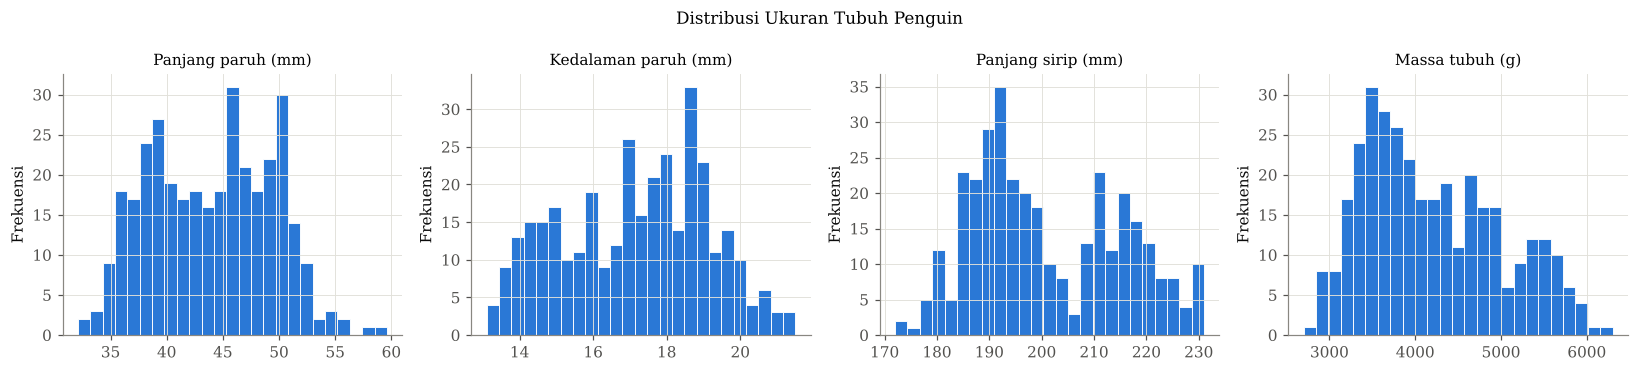

In [8]:
# Histogram — distribusi setiap fitur
labels_id = {"bill_length_mm": "Panjang paruh (mm)", "bill_depth_mm": "Kedalaman paruh (mm)",
             "flipper_length_mm": "Panjang sirip (mm)", "body_mass_g": "Massa tubuh (g)"}

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, col in zip(axes, FEATURES):
    ax.hist(df[col].dropna(), bins=25, color="#2a78d6", edgecolor="white", linewidth=0.6)
    ax.set_title(labels_id[col], fontsize=10)
    ax.set_ylabel("Frekuensi")
fig.suptitle("Distribusi Ukuran Tubuh Penguin", fontsize=11)
plt.tight_layout()
plt.show()

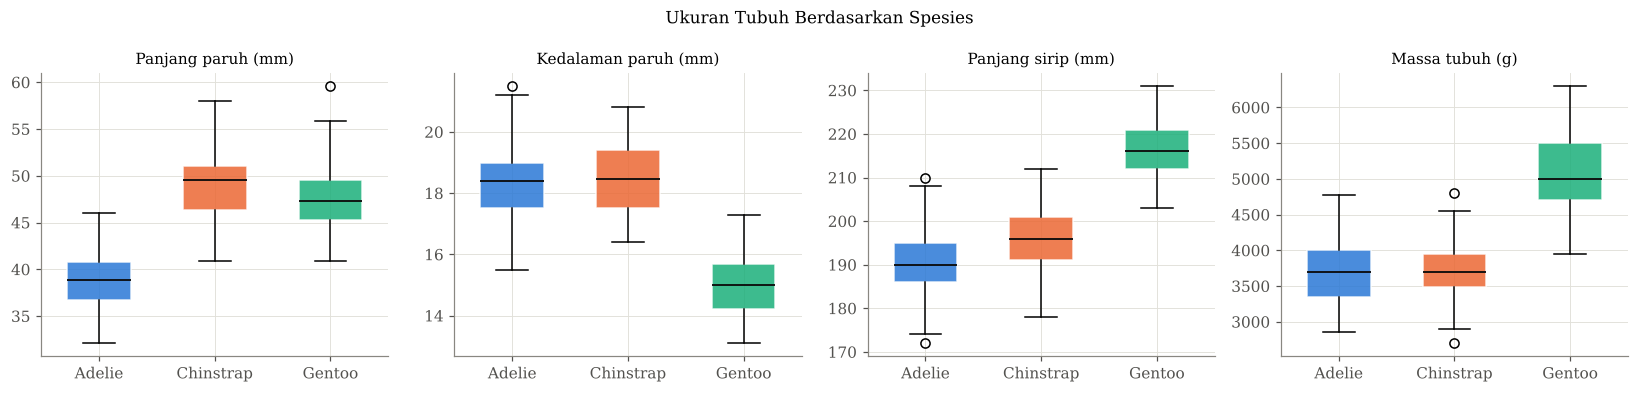

In [9]:
# Box plot per spesies — perbedaan ukuran tubuh antarspesies
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, col in zip(axes, FEATURES):
    data = [df.loc[df["species"] == s, col].dropna() for s in SPECIES]
    bp = ax.boxplot(data, patch_artist=True, widths=0.55,
                    medianprops=dict(color=INK, linewidth=1.2))
    for patch, s in zip(bp["boxes"], SPECIES):
        patch.set_facecolor(COLORS[s]); patch.set_alpha(0.85); patch.set_edgecolor("white")
    ax.set_xticks([1, 2, 3], SPECIES)
    ax.set_title(labels_id[col], fontsize=10)
fig.suptitle("Ukuran Tubuh Berdasarkan Spesies", fontsize=11)
plt.tight_layout()
simpan(fig, "eda_boxplot_spesies.png")
plt.show()

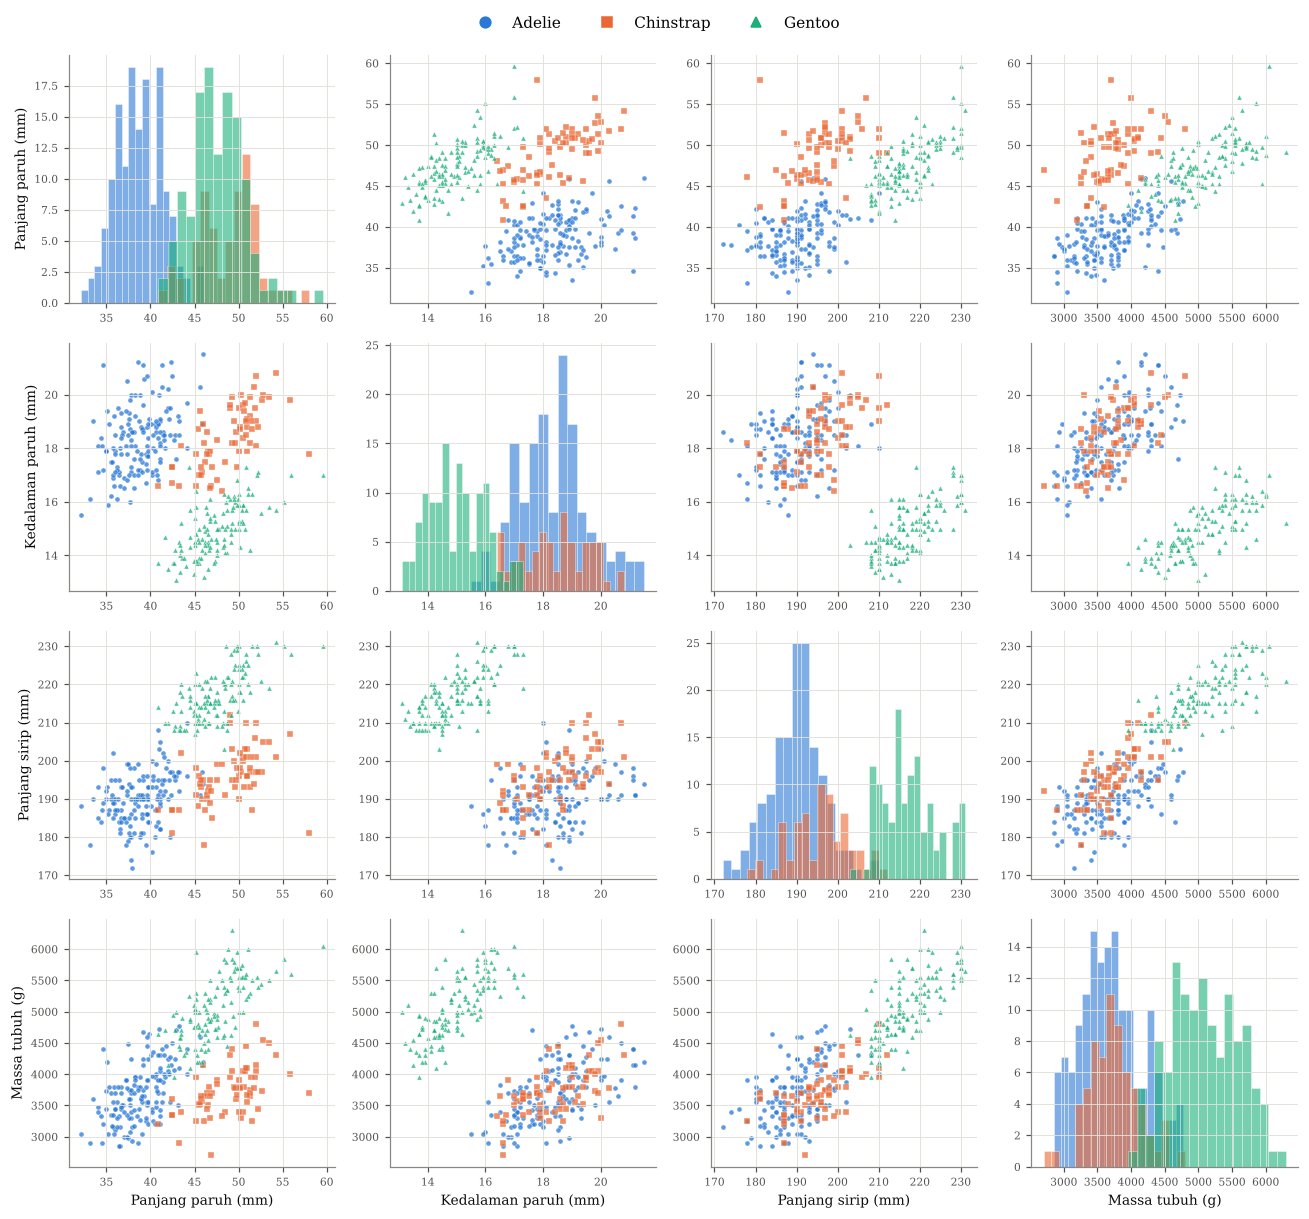

In [10]:
# Scatter matrix — hubungan antarpasangan fitur, diwarnai spesies
fig, axes = plt.subplots(4, 4, figsize=(12, 11))
for i, yc in enumerate(FEATURES):
    for j, xc in enumerate(FEATURES):
        ax = axes[i, j]
        if i == j:
            for s in SPECIES:
                ax.hist(df.loc[df["species"] == s, xc].dropna(), bins=18, alpha=0.6,
                        color=COLORS[s], edgecolor="white", linewidth=0.4)
        else:
            for s in SPECIES:
                sub = df[df["species"] == s]
                ax.scatter(sub[xc], sub[yc], s=11, alpha=0.75, color=COLORS[s],
                           marker=MARKERS[s], edgecolors="white", linewidths=0.3)
        if i == 3: ax.set_xlabel(labels_id[xc], fontsize=9)
        if j == 0: ax.set_ylabel(labels_id[yc], fontsize=9)
        ax.tick_params(labelsize=7)
handles = [Line2D([], [], marker=MARKERS[s], color=COLORS[s], linestyle="", markersize=7, label=s) for s in SPECIES]
fig.legend(handles=handles, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.01))
plt.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()

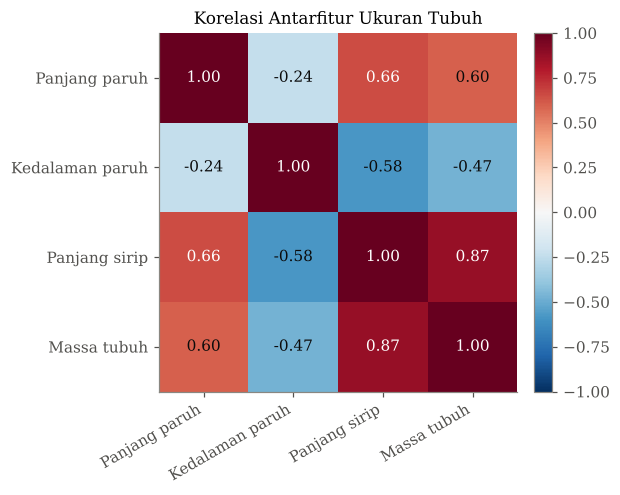

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.000,-0.235,0.656,0.595
bill_depth_mm,-0.235,1.000,-0.584,-0.472
flipper_length_mm,0.656,-0.584,1.000,0.871
body_mass_g,0.595,-0.472,0.871,1.000


In [11]:
# Matriks korelasi Pearson
corr = df[FEATURES].corr()
short = ["Panjang paruh", "Kedalaman paruh", "Panjang sirip", "Massa tubuh"]

fig, ax = plt.subplots(figsize=(5.6, 4.6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(4), short, rotation=30, ha="right")
ax.set_yticks(range(4), short)
ax.grid(False)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if abs(corr.iloc[i, j]) > 0.6 else INK, fontsize=10)
plt.colorbar(im, fraction=0.046, pad=0.04)
ax.set_title("Korelasi Antarfitur Ukuran Tubuh", fontsize=11)
plt.tight_layout()
simpan(fig, "eda_korelasi.png")
plt.show()

display(corr.round(3))

**Temuan EDA:**
- Keempat fitur **tidak berdistribusi normal sempurna**. Panjang paruh dan panjang sirip cenderung **bimodal** (dua puncak), tanda awal bahwa data mengandung lebih dari satu kelompok.
- **Gentoo** paling mudah dibedakan: sirip paling panjang (rata-rata 217,2 mm), massa tubuh terbesar (5.076 g), tetapi paruh paling tipis (15,0 mm).
- **Adelie dan Chinstrap** memiliki sirip, massa tubuh, dan kedalaman paruh yang hampir sama. Pembeda utama keduanya hanyalah **panjang paruh**: Chinstrap ±48,8 mm, Adelie ±38,8 mm.
- **Panjang sirip dan massa tubuh berkorelasi sangat kuat (r = 0,87)**, artinya keduanya membawa informasi yang mirip ("besar-kecilnya tubuh").
- Kedalaman paruh berkorelasi **negatif** dengan fitur lain pada data gabungan. Ini terjadi karena Gentoo bertubuh besar tetapi berparuh tipis, bukan karena hubungan biologis langsung.
- Skala fitur sangat berbeda: massa tubuh dalam ribuan gram (2.700–6.300), sedangkan kedalaman paruh hanya belasan milimeter (13,1–21,5). **Standardisasi wajib dilakukan** sebelum K-Means.

---
## 4. Preprocessing Data

### 4.1 Pemilihan fitur dan penanganan missing value

In [12]:
data = df.dropna(subset=FEATURES).reset_index(drop=True)

print(f"Data awal              : {len(df)} baris")
print(f"Dihapus (ukuran kosong): {len(df) - len(data)} baris")
print(f"Data untuk clustering  : {len(data)} baris")
print(f"Sisa `sex` kosong      : {data['sex'].isna().sum()} baris (tidak memengaruhi model)")
print("\nFitur yang digunakan:", FEATURES)

Data awal              : 344 baris
Dihapus (ukuran kosong): 2 baris
Data untuk clustering  : 342 baris
Sisa `sex` kosong      : 9 baris (tidak memengaruhi model)

Fitur yang digunakan: ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']


### 4.2 Pemeriksaan outlier

Outlier diperiksa dengan dua metode: **IQR** (nilai di luar Q1 − 1,5·IQR dan Q3 + 1,5·IQR) dan **Z-score** (|z| > 3). Pemeriksaan ini penting karena K-Means memakai rata-rata (centroid) yang mudah tertarik oleh nilai ekstrem.

In [13]:
rows = []
for col in FEATURES:
    s = data[col]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    z = (s - s.mean()) / s.std()
    rows.append({"fitur": col, "Q1": q1, "Q3": q3, "IQR": iqr, "batas_bawah": lo, "batas_atas": hi,
                 "min": s.min(), "max": s.max(),
                 "outlier_IQR": int(((s < lo) | (s > hi)).sum()), "outlier_Z(|z|>3)": int((z.abs() > 3).sum())})
display(pd.DataFrame(rows).round(2))

,fitur,Q1,Q3,IQR,batas_bawah,batas_atas,min,max,outlier_IQR,outlier_Z(|z|>3)
0,bill_length_mm,39.22,48.5,9.27,25.31,62.41,32.1,59.6,0,0
1,bill_depth_mm,15.60,18.7,3.10,10.95,23.35,13.1,21.5,0,0
2,flipper_length_mm,190.00,213.0,23.00,155.50,247.50,172.0,231.0,0,0
3,body_mass_g,3550.00,4750.0,1200.00,1750.00,6550.00,2700.0,6300.0,0,0


Tidak ditemukan outlier dengan metode IQR maupun Z-score. Seluruh nilai berada dalam rentang yang wajar secara biologis, sehingga **tidak ada data yang dihapus atau dibatasi**.

### 4.3 Standardisasi (*z-score*)

K-Means mengelompokkan data berdasarkan **jarak Euclidean**. Tanpa standardisasi, selisih massa tubuh (ratusan gram) akan mendominasi selisih ukuran paruh (beberapa milimeter). Karena itu setiap fitur diubah menjadi:

$$z = \frac{x - \mu}{\sigma}$$

sehingga setiap fitur memiliki rata-rata 0 dan standar deviasi 1, dan memiliki bobot yang setara dalam perhitungan jarak.

In [14]:
scaler = StandardScaler()
X = scaler.fit_transform(data[FEATURES])
X_df = pd.DataFrame(X, columns=FEATURES)

before = data[FEATURES].agg(["mean", "std", "min", "max"]).T
after = X_df.agg(["mean", "std", "min", "max"]).T
display(pd.concat({"Sebelum standardisasi": before, "Sesudah standardisasi": after}, axis=1).round(3))

Sebelum standardisasi                          Sesudah standardisasi                     
                                   mean      std     min     max                  mean    std    min    max
bill_length_mm                   43.922    5.460    32.1    59.6                   0.0  1.001 -2.169  2.876
bill_depth_mm                    17.151    1.975    13.1    21.5                   0.0  1.001 -2.054  2.205
flipper_length_mm               200.915   14.062   172.0   231.0                  -0.0  1.001 -2.059  2.143
body_mass_g                    4201.754  801.955  2700.0  6300.0                   0.0  1.001 -1.875  2.620

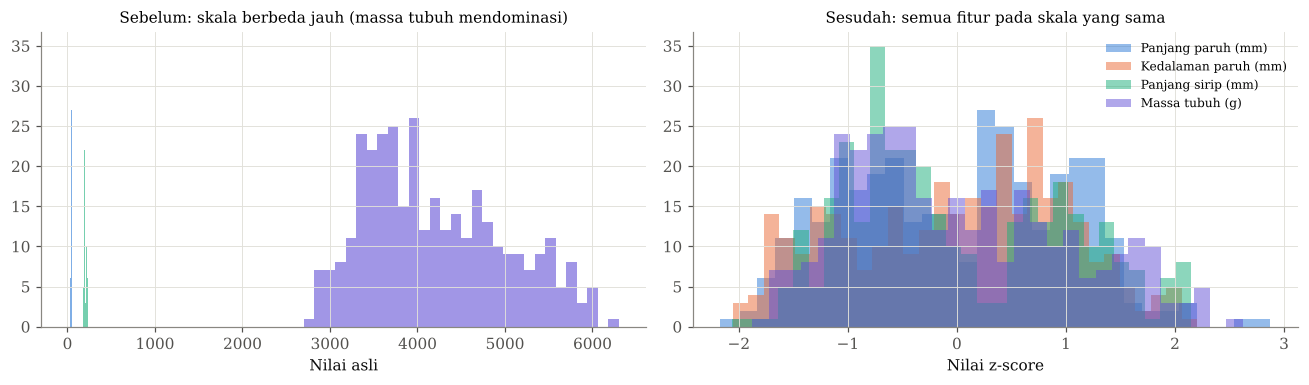

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for col, c in zip(FEATURES, ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"]):
    axes[0].hist(data[col], bins=30, alpha=0.6, color=c, label=labels_id[col])
    axes[1].hist(X_df[col], bins=30, alpha=0.5, color=c, label=labels_id[col])
axes[0].set_title("Sebelum: skala berbeda jauh (massa tubuh mendominasi)", fontsize=10)
axes[0].set_xlabel("Nilai asli")
axes[1].set_title("Sesudah: semua fitur pada skala yang sama", fontsize=10)
axes[1].set_xlabel("Nilai z-score")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

---
## 5. Menentukan Jumlah Cluster (*k*)

K-Means mengharuskan jumlah cluster ditentukan di awal. Nilai *k* dipilih dengan dua metode utama:

1. **Elbow Method** — melihat penurunan *inertia* (jumlah kuadrat jarak data ke centroid, WCSS). Titik "siku" adalah saat penambahan cluster tidak lagi menurunkan inertia secara berarti.
2. **Silhouette Score** — mengukur seberapa mirip data dengan cluster-nya sendiri dibandingkan cluster terdekat lain (Rousseeuw, 1987). Nilainya −1 sampai 1; semakin tinggi semakin baik.

Sebagai pendukung juga dihitung **Davies–Bouldin Index** (semakin kecil semakin baik) dan **Calinski–Harabasz Index** (semakin besar semakin baik).

Setiap K-Means memakai inisialisasi **k-means++** dengan 50 kali percobaan awal (`n_init=50`) dan `random_state=42` agar hasil stabil dan dapat diulang.

In [16]:
K_RANGE = range(2, 11)
rows = []
inertia_all = {1: KMeans(n_clusters=1, n_init=50, random_state=42).fit(X).inertia_}
for k in K_RANGE:
    km = KMeans(n_clusters=k, init="k-means++", n_init=50, random_state=42).fit(X)
    inertia_all[k] = km.inertia_
    rows.append({"k": k, "Inertia (WCSS)": km.inertia_,
                 "Silhouette": silhouette_score(X, km.labels_),
                 "Davies-Bouldin": davies_bouldin_score(X, km.labels_),
                 "Calinski-Harabasz": calinski_harabasz_score(X, km.labels_)})
k_table = pd.DataFrame(rows)
k_table["Penurunan inertia (%)"] = [
    (inertia_all[k - 1] - inertia_all[k]) / inertia_all[k - 1] * 100 for k in k_table["k"]]
display(k_table.round(4))

,k,Inertia (WCSS),Silhouette,Davies-Bouldin,Calinski-Harabasz,Penurunan inertia (%)
0,2,565.7076,0.5315,0.7141,482.1915,58.6471
1,3,379.3925,0.4472,0.9436,441.6771,32.9349
2,4,300.3995,0.3996,0.9442,400.4100,20.8209
3,5,232.5973,0.3782,0.9724,411.2587,22.5707
4,6,204.3926,0.3680,0.9951,382.5697,12.1260
5,7,187.0289,0.3309,1.0746,352.5527,8.4953
6,8,170.9800,0.2961,1.1515,334.0446,8.5810
7,9,158.9470,0.2877,1.1875,316.6265,7.0377
8,10,149.4244,0.2840,1.2103,300.8338,5.9911


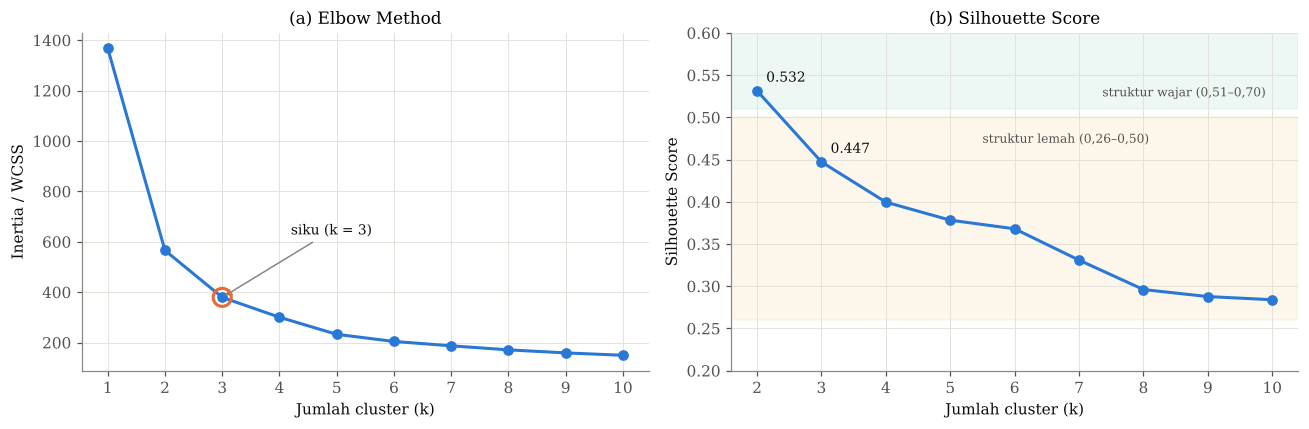

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ks = list(inertia_all.keys())
axes[0].plot(ks, list(inertia_all.values()), color="#2a78d6", linewidth=2, marker="o", markersize=6)
axes[0].scatter([3], [inertia_all[3]], s=140, facecolors="none", edgecolors="#eb6834", linewidths=2, zorder=5)
axes[0].annotate("siku (k = 3)", (3, inertia_all[3]), xytext=(4.2, inertia_all[3] + 250),
                 arrowprops=dict(arrowstyle="->", color=MUTED), fontsize=9, color=INK)
axes[0].set_xlabel("Jumlah cluster (k)")
axes[0].set_ylabel("Inertia / WCSS")
axes[0].set_title("(a) Elbow Method", fontsize=11)
axes[0].set_xticks(ks)

axes[1].plot(k_table["k"], k_table["Silhouette"], color="#2a78d6", linewidth=2, marker="o", markersize=6)
for k, s in zip(k_table["k"], k_table["Silhouette"]):
    if k in (2, 3):
        axes[1].annotate(f"{s:.3f}", (k, s), xytext=(6, 6), textcoords="offset points", fontsize=9, color=INK)
axes[1].axhspan(0.51, 0.70, color="#1baf7a", alpha=0.08)
axes[1].axhspan(0.26, 0.50, color="#eda100", alpha=0.08)
axes[1].text(9.9, 0.525, "struktur wajar (0,51–0,70)", ha="right", fontsize=8, color="#52514e")
axes[1].text(5.5, 0.47, "struktur lemah (0,26–0,50)", ha="left", fontsize=8, color="#52514e")
axes[1].set_xlabel("Jumlah cluster (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_title("(b) Silhouette Score", fontsize=11)
axes[1].set_xticks(list(K_RANGE))
axes[1].set_ylim(0.2, 0.6)

plt.tight_layout()
simpan(fig, "gambar_penentuan_k.png")
plt.show()

### 5.1 Silhouette plot untuk k = 2, 3, dan 4

Silhouette plot memperlihatkan nilai silhouette **setiap penguin** di dalam cluster-nya. Cluster yang baik memiliki batang yang lebar dan panjang, serta sedikit nilai negatif (data yang lebih dekat ke cluster lain).

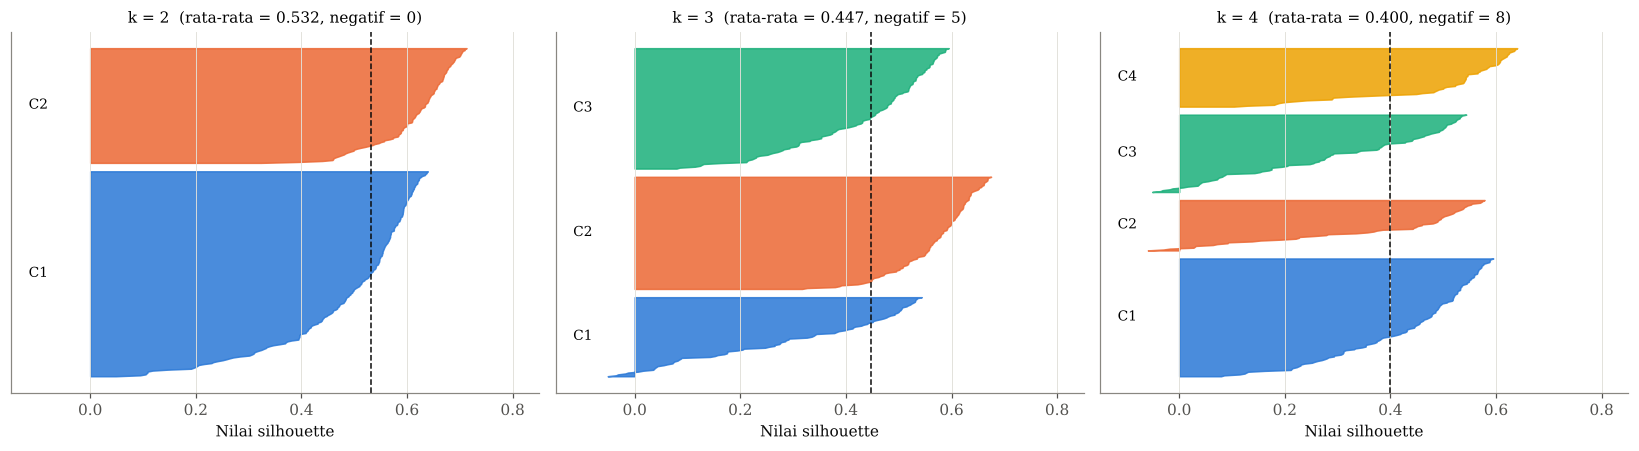

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=False)
palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
for ax, k in zip(axes, [2, 3, 4]):
    lab = KMeans(n_clusters=k, n_init=50, random_state=42).fit_predict(X)
    sil = silhouette_samples(X, lab)
    avg = sil.mean()
    y_low = 5
    for c in range(k):
        vals = np.sort(sil[lab == c])
        ax.fill_betweenx(np.arange(y_low, y_low + len(vals)), 0, vals, color=palette[c], alpha=0.85)
        ax.text(-0.08, y_low + len(vals) / 2, f"C{c+1}", fontsize=9, va="center", ha="right")
        y_low += len(vals) + 8
    ax.axvline(avg, color=INK, linestyle="--", linewidth=1)
    ax.set_title(f"k = {k}  (rata-rata = {avg:.3f}, negatif = {(sil < 0).sum()})", fontsize=10)
    ax.set_xlabel("Nilai silhouette")
    ax.set_yticks([])
    ax.set_xlim(-0.15, 0.85)
plt.tight_layout()
plt.show()

### 5.2 Keputusan jumlah cluster

| Bukti | k = 2 | k = 3 |
|---|---|---|
| Penurunan inertia dari k − 1 | 58,65% | 32,93% |
| Silhouette Score | **0,5315** (struktur wajar) | 0,4472 (struktur lemah–sedang) |
| Davies–Bouldin (kecil = baik) | **0,7141** | 0,9436 |
| Calinski–Harabasz (besar = baik) | **482,19** | 441,68 |
| Data dengan silhouette negatif | 0 | 5 |

**Apa kata setiap metode:**
- **Elbow:** penurunan inertia paling besar terjadi sampai k = 3 (58,65% lalu 32,93%). Setelah itu penurunannya mengecil menjadi ±21–23% (k = 4 dan 5) dan di bawah 13% mulai k = 6. Kurva mulai melandai di **k = 3**, walaupun sikunya tidak tajam.
- **Silhouette, Davies–Bouldin, dan Calinski–Harabasz** ketiganya paling baik di **k = 2**. Silhouette plot k = 2 menunjukkan alasannya: data terbelah sangat jelas menjadi dua kelompok besar, yaitu penguin bertubuh besar-berparuh tipis dan sisanya.
- Menurut pedoman Kaufman & Rousseeuw (1990), Silhouette 0,51–0,70 berarti struktur cluster **wajar**, sedangkan 0,26–0,50 berarti struktur **lemah** dan perlu ditafsirkan hati-hati.

**Keputusan: k = 3 dipilih sebagai model akhir**, dengan pertimbangan:
1. Metode Elbow menunjukkan titik landai di k = 3.
2. Silhouette k = 3 (0,4472) memang lebih rendah dari k = 2, tetapi masih jauh di atas 0,25 (tidak ada struktur) dan hanya 5 dari 342 penguin (1,5%) yang bernilai negatif. Cluster yang terbentuk tetap terpisah dengan cukup baik.
3. Solusi k = 2 menggabungkan dua kelompok yang ukuran paruhnya jelas berbeda (lihat bagian 8). k = 2 lebih "rapi" secara matematis, tetapi **kurang informatif** karena menyembunyikan perbedaan panjang paruh.
4. Kedua solusi tetap dilaporkan agar pembaca dapat menilai sendiri. Perbedaan rekomendasi antarmetode ini adalah temuan penting, bukan kesalahan: **tidak ada satu metrik yang selalu benar dalam menentukan k**.

---
## 6. Pemodelan K-Means

### 6.1 Model akhir (k = 3)

In [19]:
K_FINAL = 3
kmeans = KMeans(n_clusters=K_FINAL, init="k-means++", n_init=50, max_iter=300, random_state=42)
raw_labels = kmeans.fit_predict(X)

# Penomoran ulang cluster agar mudah dibaca: Cluster 1, 2, 3 diurutkan menurut
# spesies yang paling banyak di dalamnya (Adelie, Chinstrap, Gentoo).
# Ini HANYA untuk penamaan setelah model selesai; K-Means sendiri tidak pernah melihat label spesies.
dominant = pd.crosstab(raw_labels, data["species"]).idxmax(axis=1)
order = {lab: SPECIES.index(sp) + 1 for lab, sp in dominant.items()}
data["cluster"] = pd.Series(raw_labels).map(order).values

centroid_z = pd.DataFrame(kmeans.cluster_centers_, columns=FEATURES)
centroid_z.index = [order[i] for i in range(K_FINAL)]
centroid_z = centroid_z.sort_index()
centroid_asli = pd.DataFrame(scaler.inverse_transform(centroid_z), columns=FEATURES, index=centroid_z.index)

print("Jumlah iterasi sampai konvergen:", kmeans.n_iter_)
print("Inertia (WCSS):", round(kmeans.inertia_, 2))
print("\nJumlah anggota per cluster:")
display(data["cluster"].value_counts().sort_index().to_frame("jumlah_penguin"))
print("Centroid dalam satuan asli:")
display(centroid_asli.round(2))

Jumlah iterasi sampai konvergen: 5
Inertia (WCSS): 379.39

Jumlah anggota per cluster:


,jumlah_penguin
cluster,
1,132
2,87
3,123


Centroid dalam satuan asli:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
1,38.21,18.11,188.40,3584.66
2,47.53,18.76,196.90,3902.01
3,47.50,14.98,217.19,5076.02


### 6.2 Uji stabilitas inisialisasi

K-Means bergantung pada posisi centroid awal dan dapat berhenti di solusi yang kurang optimal (*local optimum*). Untuk membuktikan pentingnya `n_init`, K-Means dijalankan 30 kali dengan **satu** inisialisasi saja (`n_init=1`) dan hasilnya dibandingkan dengan model akhir.

In [20]:
stab = []
for seed in range(30):
    km1 = KMeans(n_clusters=K_FINAL, init="k-means++", n_init=1, random_state=seed).fit(X)
    stab.append({"seed": seed, "inertia": km1.inertia_,
                 "ARI vs model akhir": adjusted_rand_score(raw_labels, km1.labels_)})
stab = pd.DataFrame(stab)
same = (stab["ARI vs model akhir"] > 0.999).mean() * 100

print(f"Dari 30 percobaan dengan n_init=1, {same:.1f}% menghasilkan solusi yang sama dengan model akhir.")
print(f"Rentang inertia: {stab['inertia'].min():.2f} – {stab['inertia'].max():.2f}  (model akhir: {kmeans.inertia_:.2f})")
display(stab["ARI vs model akhir"].describe().round(3).to_frame())

Dari 30 percobaan dengan n_init=1, 30.0% menghasilkan solusi yang sama dengan model akhir.
Rentang inertia: 379.39 – 486.30  (model akhir: 379.39)


,ARI vs model akhir
count,30.000
mean,0.873
std,0.174
min,0.467
25%,0.857
50%,0.878
75%,1.000
max,1.000


**Interpretasi:** dengan satu inisialisasi saja, hanya **30%** percobaan yang menemukan solusi terbaik (inertia 379,39). Sisanya terjebak di solusi lain dengan inertia hingga 486,30, dan pada kasus terburuk kesesuaiannya dengan model akhir hanya ARI 0,467. Ini membuktikan bahwa hasil K-Means **sangat bergantung pada titik awal**. Karena itu model akhir memakai `n_init=50`: K-Means dijalankan 50 kali dari titik awal berbeda (inisialisasi k-means++; Arthur & Vassilvitskii, 2007) dan dipilih hasil dengan inertia terkecil.

---
## 7. Evaluasi Cluster

### 7.1 Silhouette Score model akhir

In [21]:
sil_all = silhouette_samples(X, data["cluster"])
data["silhouette"] = sil_all

print(f"Silhouette Score keseluruhan (k = 3): {sil_all.mean():.4f}")
print(f"Davies-Bouldin Index               : {davies_bouldin_score(X, data['cluster']):.4f}")
print(f"Calinski-Harabasz Index            : {calinski_harabasz_score(X, data['cluster']):.2f}\n")

per_cluster = data.groupby("cluster")["silhouette"].agg(
    jumlah="size", rata_rata="mean", minimum="min", maksimum="max")
per_cluster["data_negatif"] = data.groupby("cluster")["silhouette"].apply(lambda s: int((s < 0).sum()))
display(per_cluster.round(4))

Silhouette Score keseluruhan (k = 3): 0.4472
Davies-Bouldin Index               : 0.9436
Calinski-Harabasz Index            : 441.68



,jumlah,rata_rata,minimum,maksimum,data_negatif
cluster,,,,,
1,132,0.4313,0.0793,0.5947,0
2,87,0.3009,-0.0511,0.5436,5
3,123,0.5677,0.3169,0.6750,0


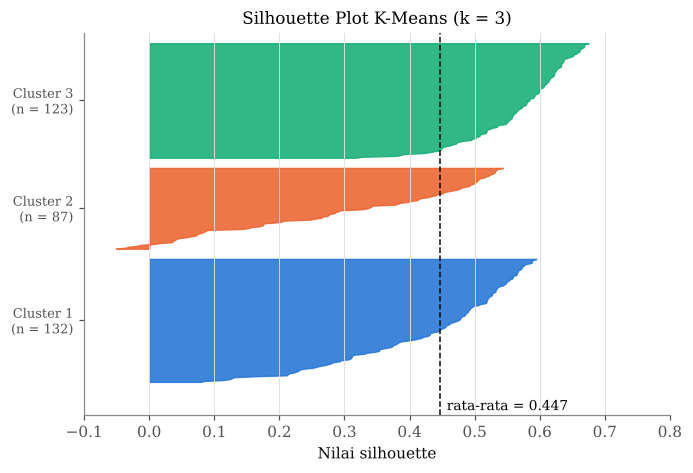

In [22]:
# Silhouette plot model akhir (untuk jurnal)
fig, ax = plt.subplots(figsize=(6.4, 4.4))
y_low = 5
cl_colors = {1: COLORS["Adelie"], 2: COLORS["Chinstrap"], 3: COLORS["Gentoo"]}
ticks, ticklabels = [], []
for c in [1, 2, 3]:
    vals = np.sort(data.loc[data["cluster"] == c, "silhouette"].values)
    ax.fill_betweenx(np.arange(y_low, y_low + len(vals)), 0, vals, color=cl_colors[c], alpha=0.9)
    ticks.append(y_low + len(vals) / 2)
    ticklabels.append(f"Cluster {c}\n(n = {len(vals)})")
    y_low += len(vals) + 10
avg = data["silhouette"].mean()
ax.axvline(avg, color=INK, linestyle="--", linewidth=1)
ax.text(avg + 0.01, -14, f"rata-rata = {avg:.3f}", fontsize=9, va="top")
ax.set_ylim(-30, y_low)
ax.set_xlabel("Nilai silhouette")
ax.set_yticks(ticks, ticklabels, fontsize=8.5)
ax.grid(axis="y", visible=False)
ax.set_xlim(-0.1, 0.8)
ax.set_title("Silhouette Plot K-Means (k = 3)", fontsize=11)
plt.tight_layout()
simpan(fig, "gambar_silhouette_k3.png")
plt.show()

### 7.2 Visualisasi cluster dengan PCA

Data memiliki 4 dimensi sehingga tidak bisa digambar langsung. **Principal Component Analysis (PCA)** dipakai **hanya untuk visualisasi**, yaitu memproyeksikan data ke 2 dimensi yang menyimpan informasi (varians) terbanyak. Proses clustering tetap dilakukan pada keempat fitur asli yang sudah distandardisasi.

In [23]:
pca = PCA(n_components=2, random_state=42)
P = pca.fit_transform(X)
data["PC1"], data["PC2"] = P[:, 0], P[:, 1]
C = pca.transform(centroid_z.values)

print("Proporsi varians PC1, PC2:", pca.explained_variance_ratio_.round(3),
      "| total:", round(pca.explained_variance_ratio_.sum(), 3))
display(pd.DataFrame(pca.components_, columns=FEATURES, index=["PC1", "PC2"]).round(3))

Proporsi varians PC1, PC2: [0.688 0.193] | total: 0.882


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
PC1,0.455,-0.400,0.576,0.548
PC2,0.597,0.798,0.002,0.084


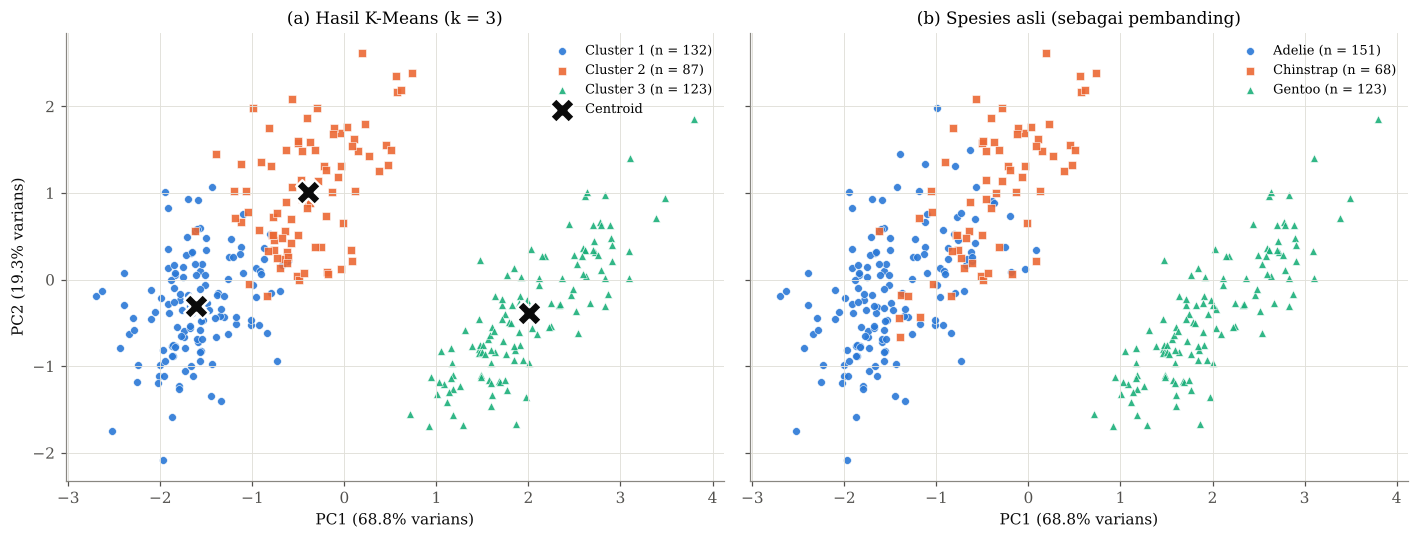

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
cl_marker = {1: "o", 2: "s", 3: "^"}

for c in [1, 2, 3]:
    sub = data[data["cluster"] == c]
    axes[0].scatter(sub["PC1"], sub["PC2"], s=26, color=cl_colors[c], marker=cl_marker[c],
                    edgecolors="white", linewidths=0.4, alpha=0.9, label=f"Cluster {c} (n = {len(sub)})")
axes[0].scatter(C[:, 0], C[:, 1], s=260, marker="X", color=INK, edgecolors="white", linewidths=1.5,
                label="Centroid", zorder=5)
axes[0].set_title("(a) Hasil K-Means (k = 3)", fontsize=11)
axes[0].legend(fontsize=8.5, loc="upper right")

for s in SPECIES:
    sub = data[data["species"] == s]
    axes[1].scatter(sub["PC1"], sub["PC2"], s=26, color=COLORS[s], marker=MARKERS[s],
                    edgecolors="white", linewidths=0.4, alpha=0.9, label=f"{s} (n = {len(sub)})")
axes[1].set_title("(b) Spesies asli (sebagai pembanding)", fontsize=11)
axes[1].legend(fontsize=8.5, loc="upper right")

ev = pca.explained_variance_ratio_ * 100
for ax in axes:
    ax.set_xlabel(f"PC1 ({ev[0]:.1f}% varians)")
axes[0].set_ylabel(f"PC2 ({ev[1]:.1f}% varians)")
plt.tight_layout()
simpan(fig, "gambar_pca_cluster_vs_spesies.png")
plt.show()

### 7.3 Profil karakteristik setiap cluster

In [25]:
profil = data.groupby("cluster")[FEATURES].agg(["mean", "std"]).round(1)
display(profil)

ringkas = data.groupby("cluster")[FEATURES].mean().round(1)
ringkas.insert(0, "jumlah", data["cluster"].value_counts().sort_index())
ringkas["silhouette"] = data.groupby("cluster")["silhouette"].mean().round(3)
display(ringkas)

bill_length_mm      bill_depth_mm      flipper_length_mm      body_mass_g       
                  mean  std          mean  std              mean  std        mean    std
cluster                                                                                 
1                 38.2  2.2          18.1  1.2             188.4  5.7      3584.7  406.6
2                 47.5  3.9          18.8  1.1             196.9  6.3      3902.0  411.3
3                 47.5  3.1          15.0  1.0             217.2  6.5      5076.0  504.1

,jumlah,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,silhouette
cluster,,,,,,
1,132,38.2,18.1,188.4,3584.7,0.431
2,87,47.5,18.8,196.9,3902.0,0.301
3,123,47.5,15.0,217.2,5076.0,0.568


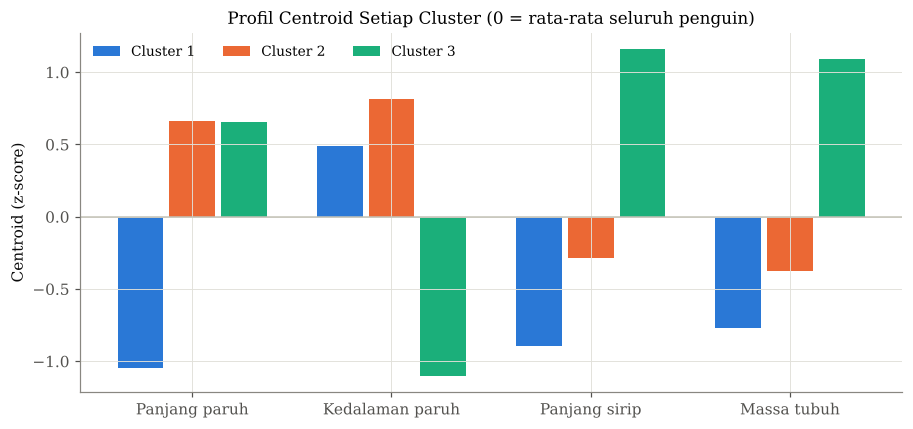

In [26]:
# Profil centroid (z-score): posisi setiap cluster relatif terhadap rata-rata seluruh penguin
fig, ax = plt.subplots(figsize=(8.4, 4))
w = 0.26
x = np.arange(len(FEATURES))
for i, c in enumerate([1, 2, 3]):
    vals = centroid_z.loc[c].values
    ax.bar(x + (i - 1) * w, vals, width=w - 0.03, color=cl_colors[c], label=f"Cluster {c}")
ax.axhline(0, color="#c3c2b7", linewidth=1)
ax.set_xticks(x, short)
ax.set_ylabel("Centroid (z-score)")
ax.set_title("Profil Centroid Setiap Cluster (0 = rata-rata seluruh penguin)", fontsize=11)
ax.legend(ncol=3, fontsize=9, loc="upper left")
plt.tight_layout()
simpan(fig, "gambar_profil_centroid.png")
plt.show()

**Interpretasi profil cluster:**

| Cluster | Jumlah | Ciri fisik utama | Label deskriptif |
|---|---|---|---|
| **Cluster 1** | 132 | Paruh **paling pendek** (38,2 mm) tetapi tebal (18,1 mm); sirip pendek (188,4 mm); massa tubuh paling ringan (3.584,7 g) | *Bertubuh kecil, paruh pendek-tebal* |
| **Cluster 2** | 87 | Paruh **panjang** (47,5 mm) **dan paling tebal** (18,8 mm); sirip dan massa tubuh sedang (196,9 mm; 3.902,0 g) | *Bertubuh sedang, paruh panjang-tebal* |
| **Cluster 3** | 123 | Paruh panjang (47,5 mm) tetapi **paling tipis** (15,0 mm); sirip **paling panjang** (217,2 mm); massa tubuh **paling berat** (5.076,0 g) | *Bertubuh besar, paruh panjang-tipis* |

- **Cluster 3 paling kompak dan terpisah** (silhouette rata-rata 0,568, tanpa nilai negatif). Kombinasi tubuh besar dan paruh tipis sangat khas dan tidak dimiliki kelompok lain.
- **Cluster 1 cukup baik** (silhouette 0,431). Pembeda utamanya adalah paruh yang jauh lebih pendek.
- **Cluster 2 paling lemah** (silhouette 0,301, dengan 5 nilai negatif). Cluster ini berada **di antara** Cluster 1 dan 3: paruhnya sepanjang Cluster 3, tetapi tebal paruh dan ukuran tubuhnya mendekati Cluster 1. Ini terlihat juga pada grafik PCA, di mana Cluster 2 bersinggungan dengan Cluster 1.
- **Cluster 2 dan 3 memiliki panjang paruh yang hampir sama** (47,5 mm). Yang membedakan keduanya adalah **kedalaman paruh dan besar tubuh**, sedangkan yang membedakan Cluster 1 dan 2 adalah **panjang paruh**.
- Pada grafik PCA, PC1 (68,8% varians) terutama mewakili **besar tubuh** (panjang sirip dan massa tubuh), sedangkan PC2 (19,3%) terutama mewakili **ukuran paruh**. Kedua komponen menyimpan 88,2% informasi, sehingga gambar 2 dimensi ini cukup mewakili data asli.

---
## 8. Validasi terhadap Spesies Asli

Karena dataset ini menyimpan label spesies, hasil clustering dapat diuji secara **eksternal**: apakah kelompok yang ditemukan K-Means tanpa label sesuai dengan spesies sebenarnya? Ukuran yang dipakai:

- **Tabel silang** (*contingency table*) antara cluster dan spesies.
- **Adjusted Rand Index (ARI)** — kesesuaian dua pengelompokan; 1 = identik, ±0 = setara pengelompokan acak (Hubert & Arabie, 1985).
- **Normalized Mutual Information (NMI)** — seberapa banyak informasi spesies yang terkandung dalam label cluster; 0 sampai 1.

In [27]:
ct = pd.crosstab(data["cluster"], data["species"], margins=True, margins_name="Total")
display(ct)

ari = adjusted_rand_score(data["species"], data["cluster"])
nmi = normalized_mutual_info_score(data["species"], data["cluster"])
cocok = sum(pd.crosstab(data["cluster"], data["species"]).max(axis=1))
print(f"Adjusted Rand Index (ARI)        : {ari:.4f}")
print(f"Normalized Mutual Information    : {nmi:.4f}")
print(f"Penguin pada spesies dominan cluster-nya: {cocok} dari {len(data)} ({cocok/len(data)*100:.2f}%)")

species,Adelie,Chinstrap,Gentoo,Total
cluster,,,,
1,127,5,0,132
2,24,63,0,87
3,0,0,123,123
Total,151,68,123,342


Adjusted Rand Index (ARI)        : 0.7928
Normalized Mutual Information    : 0.7855
Penguin pada spesies dominan cluster-nya: 313 dari 342 (91.52%)


In [28]:
# Cluster vs spesies & jenis kelamin — siapa yang "salah kelompok"?
display(pd.crosstab(data["cluster"], [data["species"], data["sex"].fillna("tidak diketahui")]))

salah = data[((data["cluster"] == 1) & (data["species"] != "Adelie")) |
             ((data["cluster"] == 2) & (data["species"] != "Chinstrap")) |
             ((data["cluster"] == 3) & (data["species"] != "Gentoo"))]
print(f"Penguin yang tidak berada di cluster spesies dominannya: {len(salah)}")
display(salah.groupby(["species", "sex", "cluster"]).size().to_frame("jumlah"))
display(salah.groupby(["species", "cluster"])[FEATURES].mean().round(1))

species Adelie                      Chinstrap      Gentoo                     
sex     female male tidak diketahui    female male female male tidak diketahui
cluster                                                                       
1           73   50               4         5    0      0    0               0
2            0   23               1        29   34      0    0               0
3            0    0               0         0    0     58   61               4

Penguin yang tidak berada di cluster spesies dominannya: 29


,,,jumlah
species,sex,cluster,
Adelie,male,2,23
Chinstrap,female,1,5


,,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
species,cluster,,,,
Adelie,2,42.7,19.3,197.6,4251.0
Chinstrap,1,42.3,16.9,185.8,3280.0


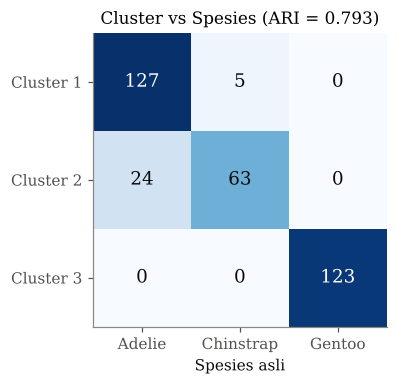

In [29]:
# Grafik tabel silang untuk jurnal
mat = pd.crosstab(data["cluster"], data["species"]).reindex(columns=SPECIES)
fig, ax = plt.subplots(figsize=(5.4, 3.6))
im = ax.imshow(mat.values, cmap="Blues")
ax.grid(False)
ax.set_xticks(range(3), SPECIES)
ax.set_yticks(range(3), [f"Cluster {c}" for c in mat.index])
for i in range(3):
    for j in range(3):
        v = mat.values[i, j]
        ax.text(j, i, v, ha="center", va="center", fontsize=12,
                color="white" if v > mat.values.max() / 2 else INK)
ax.set_xlabel("Spesies asli")
ax.set_title(f"Cluster vs Spesies (ARI = {ari:.3f})", fontsize=11)
plt.tight_layout()
simpan(fig, "gambar_tabel_silang.png")
plt.show()

In [30]:
# Pembanding: hasil k = 2 (pilihan Silhouette tertinggi)
lab2 = KMeans(n_clusters=2, n_init=50, random_state=42).fit_predict(X)
print("Tabel silang k = 2:")
display(pd.crosstab(lab2 + 1, data["species"], rownames=["cluster (k=2)"]))
print(f"ARI k = 2: {adjusted_rand_score(data['species'], lab2):.4f} | Silhouette k = 2: {silhouette_score(X, lab2):.4f}")

Tabel silang k = 2:


species,Adelie,Chinstrap,Gentoo
cluster (k=2),,,
1,151,68,0
2,0,0,123


ARI k = 2: 0.6551 | Silhouette k = 2: 0.5315


**Interpretasi validasi eksternal:**

1. **K-Means berhasil menemukan kembali struktur spesies tanpa pernah melihat labelnya.** Sebanyak **313 dari 342 penguin (91,52%)** berada di cluster yang didominasi spesiesnya sendiri, dengan **ARI = 0,7928** dan **NMI = 0,7855**.
2. **Cluster 3 identik dengan Gentoo:** seluruh 123 Gentoo masuk Cluster 3, tanpa satu pun spesies lain. Ini sesuai dengan EDA: Gentoo memiliki bentuk tubuh yang paling berbeda.
3. **Kesalahan hanya terjadi antara Adelie dan Chinstrap**, dan polanya sangat sistematis:
   - **23 Adelie jantan** (serta 1 Adelie tanpa data jenis kelamin) masuk Cluster 2 (didominasi Chinstrap). Rata-rata paruh mereka 42,7 mm, lebih panjang dari rata-rata Adelie (38,8 mm), dan massa tubuhnya 4.251 g, lebih berat dari rata-rata Adelie (3.700,7 g).
   - **5 Chinstrap betina** masuk Cluster 1 (didominasi Adelie). Paruh mereka hanya 42,3 mm, jauh lebih pendek dari rata-rata Chinstrap (48,8 mm), dan tubuhnya ringan (3.280 g).
   - Artinya, **Adelie jantan yang berukuran besar menyerupai Chinstrap, dan Chinstrap betina yang kecil menyerupai Adelie.** Perbedaan ukuran tubuh antara jantan dan betina (*sexual dimorphism*) mengaburkan batas antarspesies. Fenomena ini memang menjadi pokok kajian penelitian asal dataset (Gorman et al., 2014) dan diuji lebih lanjut di bagian 9.2.
4. **Solusi k = 2** hanya memisahkan Gentoo dari gabungan Adelie + Chinstrap (ARI 0,6551). Silhouette-nya lebih tinggi karena pemisahan Gentoo memang sangat jelas, tetapi solusi ini kehilangan informasi tentang perbedaan panjang paruh. Hal ini memperkuat keputusan memilih k = 3.

---
## 9. Analisis Lanjutan

### 9.1 Pengaruh standardisasi

Untuk membuktikan pentingnya standardisasi, K-Means (k = 3) juga dijalankan pada data **tanpa** standardisasi.

In [31]:
km_raw = KMeans(n_clusters=3, n_init=50, random_state=42).fit(data[FEATURES])
skenario = pd.DataFrame([
    {"Skenario": "Tanpa standardisasi", "Silhouette": silhouette_score(data[FEATURES], km_raw.labels_),
     "ARI vs spesies": adjusted_rand_score(data["species"], km_raw.labels_)},
    {"Skenario": "Dengan standardisasi (model akhir)", "Silhouette": sil_all.mean(), "ARI vs spesies": ari},
])
display(skenario.round(4))
print("Tabel silang tanpa standardisasi:")
display(pd.crosstab(km_raw.labels_ + 1, data["species"], rownames=["cluster"]))
print("Rata-rata massa tubuh per cluster (tanpa standardisasi):")
display(data.groupby(km_raw.labels_ + 1)["body_mass_g"].agg(["mean", "min", "max"]).round(0))

,Skenario,Silhouette,ARI vs spesies
0,Tanpa standardisasi,0.5752,0.3191
1,Dengan standardisasi (model akhir),0.4472,0.7928


Tabel silang tanpa standardisasi:


species,Adelie,Chinstrap,Gentoo
cluster,,,
1,112,52,1
2,0,0,70
3,39,16,52


Rata-rata massa tubuh per cluster (tanpa standardisasi):


,mean,min,max
1,3518.0,2700.0,3975.0
2,5435.0,4950.0,6300.0
3,4449.0,4000.0,4925.0


**Interpretasi:** tanpa standardisasi, Silhouette Score justru **lebih tinggi** (0,5752), tetapi kesesuaian dengan spesies **anjlok** dari ARI 0,7928 menjadi **0,3191**. Tabel rata-rata massa tubuh menjelaskan penyebabnya: tanpa standardisasi, K-Means **hanya membagi penguin berdasarkan massa tubuh** (ringan < ±4.000 g, sedang ±4.000–4.900 g, berat > ±4.950 g), karena selisih massa tubuh (ratusan gram) jauh lebih besar daripada selisih ukuran paruh (beberapa milimeter). Panjang dan kedalaman paruh, yang justru menjadi pembeda penting Adelie dan Chinstrap, hampir diabaikan.

Temuan ini memberi dua pelajaran:
1. **Standardisasi wajib** pada algoritma berbasis jarak seperti K-Means.
2. **Silhouette Score dari ruang fitur yang berbeda tidak dapat dibandingkan secara langsung.** Skor yang lebih tinggi pada data tanpa standardisasi tidak berarti pengelompokannya lebih baik; skor itu hanya mengukur seberapa rapi data terbagi menurut massa tubuh.

### 9.2 Pengaruh jenis kelamin (*sexual dimorphism*)

Tabel silang di bagian 8 menunjukkan bahwa penguin yang "salah kelompok" didominasi oleh jenis kelamin tertentu. Untuk menguji dugaan ini, K-Means dijalankan **terpisah** untuk penguin betina dan jantan.

In [32]:
rows = []
for sx in ["female", "male"]:
    sub = data[data["sex"] == sx]
    Xs = StandardScaler().fit_transform(sub[FEATURES])
    lab = KMeans(n_clusters=3, n_init=50, random_state=42).fit_predict(Xs)
    rows.append({"Kelompok": "Betina" if sx == "female" else "Jantan", "n": len(sub),
                 "Silhouette": silhouette_score(Xs, lab), "ARI vs spesies": adjusted_rand_score(sub["species"], lab)})
    print(f"Tabel silang — {sx}:")
    display(pd.crosstab(lab + 1, sub["species"], rownames=["cluster"]))
rows.append({"Kelompok": "Gabungan (model akhir)", "n": len(data), "Silhouette": sil_all.mean(), "ARI vs spesies": ari})
display(pd.DataFrame(rows).round(4))

Tabel silang — female:


species,Adelie,Chinstrap,Gentoo
cluster,,,
1,73,5,0
2,0,0,58
3,0,29,0


Tabel silang — male:


species,Adelie,Chinstrap,Gentoo
cluster,,,
1,2,34,0
2,0,0,61
3,71,0,0


,Kelompok,n,Silhouette,ARI vs spesies
0,Betina,165,0.5457,0.9188
1,Jantan,168,0.5487,0.9673
2,Gabungan (model akhir),342,0.4472,0.7928


**Interpretasi:** dugaan di bagian 8 terbukti. Ketika penguin betina dan jantan dikelompokkan **terpisah**:
- Silhouette Score naik dari 0,4472 menjadi **0,5457 (betina)** dan **0,5487 (jantan)**, keduanya masuk kategori struktur **wajar** menurut Kaufman & Rousseeuw (1990).
- Kesesuaian dengan spesies naik dari ARI 0,7928 menjadi **0,9188 (betina)** dan **0,9673 (jantan)**. Pada kelompok jantan hanya 2 penguin yang tidak sesuai spesiesnya, dan pada kelompok betina hanya 5.

Artinya, **sebagian besar "kesalahan" pada model gabungan disebabkan oleh perbedaan ukuran tubuh jantan dan betina**, bukan karena K-Means gagal. Penguin jantan umumnya lebih besar dari betina pada spesies yang sama, sehingga ketika keduanya digabung, Adelie jantan yang besar tumpang tindih dengan Chinstrap. Catatan: analisis ini hanya memakai 333 penguin yang jenis kelaminnya diketahui, dan model utama tetap memakai data gabungan karena soal meminta pengelompokan berdasarkan ukuran tubuh.

### 9.3 Sensitivitas pemilihan fitur

Panjang sirip dan massa tubuh berkorelasi sangat kuat (r = 0,87). Bagian ini menguji bagaimana hasil berubah jika kombinasi fitur diubah.

In [33]:
subsets = {
    "4 fitur (model akhir)": FEATURES,
    "Tanpa massa tubuh": ["bill_length_mm", "bill_depth_mm", "flipper_length_mm"],
    "Tanpa panjang sirip": ["bill_length_mm", "bill_depth_mm", "body_mass_g"],
    "Hanya ukuran paruh": ["bill_length_mm", "bill_depth_mm"],
    "Hanya ukuran tubuh (sirip + massa)": ["flipper_length_mm", "body_mass_g"],
}
rows = []
for nama, feats in subsets.items():
    Xs = StandardScaler().fit_transform(data[feats])
    lab = KMeans(n_clusters=3, n_init=50, random_state=42).fit_predict(Xs)
    rows.append({"Kombinasi fitur": nama, "Jumlah fitur": len(feats),
                 "Silhouette": silhouette_score(Xs, lab), "ARI vs spesies": adjusted_rand_score(data["species"], lab)})
display(pd.DataFrame(rows).round(4))

,Kombinasi fitur,Jumlah fitur,Silhouette,ARI vs spesies
0,4 fitur (model akhir),4,0.4472,0.7928
1,Tanpa massa tubuh,3,0.5018,0.9224
2,Tanpa panjang sirip,3,0.4778,0.9078
3,Hanya ukuran paruh,2,0.5245,0.8259
4,Hanya ukuran tubuh (sirip + massa),2,0.4627,0.4226


**Interpretasi:**
- **Membuang massa tubuh** justru menaikkan kesesuaian dengan spesies (ARI 0,7928 → **0,9224**) dan Silhouette (0,4472 → 0,5018). Massa tubuh sangat dipengaruhi jenis kelamin dan sudah terwakili oleh panjang sirip (r = 0,87). Akibatnya, informasi "besar tubuh" terhitung dua kali dan memperkuat efek *sexual dimorphism*.
- **Hanya ukuran paruh** menghasilkan Silhouette tertinggi (0,5245) dengan ARI 0,8259. Paruh adalah ciri pembeda spesies yang paling kuat.
- **Hanya ukuran tubuh (sirip + massa)** menghasilkan ARI terendah (0,4226), karena Adelie dan Chinstrap hampir sama besar dan hanya bisa dibedakan dari paruhnya.

Jadi pemilihan fitur sangat memengaruhi hasil clustering. Model akhir tetap memakai keempat fitur agar sesuai dengan bunyi soal (berdasarkan ukuran tubuh **dan** karakteristik fisik). Hasil ini menjadi saran untuk penelitian lanjutan, misalnya seleksi fitur atau pembobotan fitur sebelum clustering.

---
## 10. Ringkasan Hasil untuk Artikel Jurnal

In [34]:
ringkasan = pd.DataFrame([
    ["Jumlah data awal / dipakai", f"{len(df)} / {len(data)} penguin"],
    ["Fitur", "panjang paruh, kedalaman paruh, panjang sirip, massa tubuh"],
    ["Preprocessing", "hapus 2 baris tanpa ukuran; tidak ada duplikat & outlier; standardisasi z-score"],
    ["k terpilih", "3 (Elbow + Silhouette + interpretasi)"],
    ["Silhouette Score k = 2", f"{k_table.loc[k_table['k'] == 2, 'Silhouette'].item():.4f}"],
    ["Silhouette Score k = 3 (model akhir)", f"{sil_all.mean():.4f}"],
    ["Davies-Bouldin k = 3", f"{davies_bouldin_score(X, data['cluster']):.4f}"],
    ["ARI / NMI terhadap spesies", f"{ari:.4f} / {nmi:.4f}"],
    ["Kesesuaian dengan spesies dominan", f"{cocok} dari {len(data)} ({cocok/len(data)*100:.2f}%)"],
    ["ARI tanpa standardisasi", f"{adjusted_rand_score(data['species'], km_raw.labels_):.4f}"],
], columns=["Aspek", "Hasil"])
display(ringkasan)

print("Grafik yang tersimpan untuk jurnal:")
for f in sorted(os.listdir(OUT_DIR)):
    print(" -", os.path.join(OUT_DIR, f))

,Aspek,Hasil
0,Jumlah data awal / dipakai,344 / 342 penguin
1,Fitur,"panjang paruh, kedalaman paruh, panjang sirip,..."
2,Preprocessing,hapus 2 baris tanpa ukuran; tidak ada duplikat...
3,k terpilih,3 (Elbow + Silhouette + interpretasi)
4,Silhouette Score k = 2,0.5315
5,Silhouette Score k = 3 (model akhir),0.4472
6,Davies-Bouldin k = 3,0.9436
7,ARI / NMI terhadap spesies,0.7928 / 0.7855
8,Kesesuaian dengan spesies dominan,313 dari 342 (91.52%)
9,ARI tanpa standardisasi,0.3191


Grafik yang tersimpan untuk jurnal:
 - gambar_jurnal/eda_boxplot_spesies.png
 - gambar_jurnal/eda_korelasi.png
 - gambar_jurnal/gambar_pca_cluster_vs_spesies.png
 - gambar_jurnal/gambar_penentuan_k.png
 - gambar_jurnal/gambar_profil_centroid.png
 - gambar_jurnal/gambar_silhouette_k3.png
 - gambar_jurnal/gambar_tabel_silang.png


---
## 11. Kesimpulan

1. **Kualitas data.** Dataset Palmer Penguins tergolong bersih: tidak ada duplikat maupun outlier. Hanya 2 dari 344 baris yang dihapus karena tidak memiliki ukuran tubuh sama sekali. Tantangan utamanya adalah **perbedaan skala** antarfitur, sehingga standardisasi z-score menjadi langkah preprocessing yang paling menentukan. Tanpa standardisasi, kesesuaian dengan spesies turun dari ARI 0,7928 menjadi 0,3191.
2. **Jumlah cluster.** Elbow Method menunjukkan titik landai di k = 3, sedangkan Silhouette Score tertinggi ada di k = 2 (0,5315). Dipilih **k = 3** karena memberikan pengelompokan yang lebih informatif dengan Silhouette yang masih memadai.
3. **Hasil K-Means (k = 3)** menghasilkan tiga kelompok morfologi yang jelas:
   - Cluster 1: bertubuh kecil, paruh pendek-tebal (132 penguin).
   - Cluster 2: bertubuh sedang, paruh panjang-tebal (87 penguin).
   - Cluster 3: bertubuh besar, paruh panjang-tipis (123 penguin).
4. **Evaluasi Silhouette Score** keseluruhan sebesar **0,4472**. Cluster 3 paling kompak (0,568), Cluster 1 cukup baik (0,431), dan Cluster 2 paling lemah (0,301) karena posisinya berada di antara dua kelompok lain.
5. **Validasi terhadap spesies** menunjukkan bahwa K-Means, tanpa melihat label, mampu mengelompokkan **91,52%** penguin sesuai spesies dominan (ARI 0,7928). Gentoo dikenali sempurna. Kesalahan hanya terjadi antara Adelie jantan dan Chinstrap betina yang ukurannya tumpang tindih. Jika betina dan jantan dikelompokkan terpisah, ARI naik menjadi 0,92–0,97.

**Saran:** penelitian lanjutan dapat (a) mempertimbangkan jenis kelamin dalam analisis, (b) melakukan seleksi atau pembobotan fitur karena massa tubuh terbukti mengaburkan batas spesies, dan (c) membandingkan K-Means dengan metode lain seperti *Gaussian Mixture Model* atau *Hierarchical Clustering*.

---
## Daftar Pustaka

Arthur, D., & Vassilvitskii, S. (2007). k-means++: The advantages of careful seeding. In *Proceedings of the Eighteenth Annual ACM-SIAM Symposium on Discrete Algorithms* (pp. 1027–1035). Society for Industrial and Applied Mathematics.

Gorman, K. B., Williams, T. D., & Fraser, W. R. (2014). Ecological sexual dimorphism and environmental variability within a community of Antarctic penguins (genus *Pygoscelis*). *PLoS ONE, 9*(3), e90081. https://doi.org/10.1371/journal.pone.0090081

Horst, A. M., Hill, A. P., & Gorman, K. B. (2020). *palmerpenguins: Palmer Archipelago (Antarctica) penguin data* (R package version 0.1.0). https://doi.org/10.5281/zenodo.3960218

Hubert, L., & Arabie, P. (1985). Comparing partitions. *Journal of Classification, 2*(1), 193–218. https://doi.org/10.1007/BF01908075

Kaufman, L., & Rousseeuw, P. J. (1990). *Finding groups in data: An introduction to cluster analysis*. John Wiley & Sons.

MacQueen, J. (1967). Some methods for classification and analysis of multivariate observations. In *Proceedings of the Fifth Berkeley Symposium on Mathematical Statistics and Probability* (Vol. 1, pp. 281–297). University of California Press.

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53–65. https://doi.org/10.1016/0377-0427(87)90125-7

Thorndike, R. L. (1953). Who belongs in the family? *Psychometrika, 18*(4), 267–276. https://doi.org/10.1007/BF02289263